# Learned Delay Dynamics Analysis

This notebook analyzes saved delay-learning `.pt` checkpoints produced by the learnable lag mixer.

It covers:
- loading multiple checkpoints or a saved history file
- heatmaps of `delay_probs` for selected output neurons across early, mid, and final stages
- final discrete delay heatmaps from `rounded_delays` or `discrete_delay_onehot`
- delay histograms over training
- fraction of connections assigned to each lag over time
- the relationship between learned delay and `|weight|`
- detection of unused or suppressed lags such as `lag=1`


In [35]:
from __future__ import annotations

from pathlib import Path
from typing import Iterable

import json

import h5py
import math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown
from scipy.ndimage import gaussian_filter1d

plt.style.use("default")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
})


REQUIRED_KEYS = {"delay_probs", "effective_delays", "rounded_delays", "weights", "lags"}


def _to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def _to_scalar(x, default=np.nan):
    if x is None:
        return default
    if isinstance(x, torch.Tensor):
        if x.numel() == 1:
            return x.detach().cpu().item()
        return default
    if np.isscalar(x):
        return x
    return default


def _is_analysis_record(obj):
    return isinstance(obj, dict) and REQUIRED_KEYS.issubset(obj.keys())


def load_delay_records(path_like):
    path = Path(path_like).expanduser().resolve()
    payload = torch.load(path, map_location="cpu", weights_only=False)

    if _is_analysis_record(payload):
        records = [payload]
    elif isinstance(payload, list) and payload and all(_is_analysis_record(x) for x in payload):
        records = payload
    else:
        raise ValueError(
            f"{path} does not look like a delay-analysis checkpoint or history file. "
            f"Top-level type: {type(payload).__name__}"
        )

    normalized = []
    for idx, record in enumerate(records):
        item = dict(record)
        item["source_path"] = str(path)
        item["source_file"] = path.name
        item["record_index"] = idx
        item["epoch_value"] = _to_scalar(item.get("epoch"), default=np.nan)
        item["step_value"] = _to_scalar(item.get("step"), default=np.nan)
        item["lags_np"] = _to_numpy(item["lags"]).astype(int)
        normalized.append(item)
    return normalized


def collect_records(paths: Iterable[Path]):
    records = []
    for path in paths:
        records.extend(load_delay_records(path))
    if not records:
        raise ValueError("No delay-analysis records were loaded.")

    all_lag_tuples = {tuple(r["lags_np"].tolist()) for r in records}
    if len(all_lag_tuples) != 1:
        raise ValueError(f"Loaded checkpoints use inconsistent lag sets: {all_lag_tuples}")

    for idx, record in enumerate(records):
        epoch = record["epoch_value"]
        step = record["step_value"]
        sort_epoch = epoch if np.isfinite(epoch) else np.nan
        sort_step = step if np.isfinite(step) else np.nan
        record["sort_key"] = (
            0 if np.isfinite(sort_epoch) else 1,
            sort_epoch if np.isfinite(sort_epoch) else np.inf,
            sort_step if np.isfinite(sort_step) else np.inf,
            idx,
        )

    return sorted(records, key=lambda r: r["sort_key"])


def resolve_run_dir(logs_root, run_name):
    logs_root = Path(logs_root).expanduser().resolve()
    direct = logs_root / run_name
    if direct.exists():
        return direct

    matches = sorted(logs_root.glob(f"**/{run_name}"))
    matches = [p for p in matches if p.is_dir()]
    if not matches:
        raise FileNotFoundError(
            f"Could not find run '{run_name}' under {logs_root}. "
            "Expected either logs_root/run_name or logs_root/<date>/run_name."
        )
    if len(matches) > 1:
        raise ValueError(f"Run name '{run_name}' matched multiple directories: {[str(p) for p in matches]}")
    return matches[0]


def discover_run_delay_paths(run_dir, block_index=0, include_best=True, include_final=True):
    run_dir = Path(run_dir).expanduser().resolve()
    delay_root = run_dir / "spiking_stats" / "delay_dynamics"
    block_name = f"block_{block_index:02d}.pt"

    if not delay_root.exists():
        raise FileNotFoundError(
            f"No delay dynamics directory found at {delay_root}. "
            "Train the model with delay snapshot saving enabled first."
        )

    validation_paths = sorted((delay_root / "validation").glob(f"**/{block_name}"))
    chosen_paths = list(validation_paths)

    if include_best:
        best_path = delay_root / "best" / block_name
        if best_path.exists():
            chosen_paths.append(best_path)

    if include_final:
        final_path = delay_root / "final" / block_name
        if final_path.exists():
            chosen_paths.append(final_path)

    if not chosen_paths:
        raise FileNotFoundError(
            f"Found {delay_root}, but no files matching {block_name}."
        )

    return chosen_paths


def select_stage_records(records, labels=("early", "mid", "final")):
    if len(records) == 1:
        return {labels[0]: records[0], labels[-1]: records[0]}
    indices = np.linspace(0, len(records) - 1, num=min(len(labels), len(records)), dtype=int)
    chosen = {}
    for label, idx in zip(labels, indices):
        chosen[label] = records[int(idx)]
    if "final" not in chosen:
        chosen["final"] = records[-1]
    return chosen


def format_record_label(record, fallback):
    epoch = record.get("epoch_value", np.nan)
    step = record.get("step_value", np.nan)
    bits = [fallback]
    if np.isfinite(epoch):
        bits.append(f"epoch={int(epoch)}")
    if np.isfinite(step):
        bits.append(f"step={int(step)}")
    return " | ".join(bits)


def chosen_discrete_delays(record, prefer_onehot=False):
    if prefer_onehot and "discrete_delay_onehot" in record:
        onehot = _to_numpy(record["discrete_delay_onehot"])
        lag_indices = onehot.argmax(axis=-1)
        return record["lags_np"][lag_indices]
    return _to_numpy(record["rounded_delays"]).astype(int)


def lag_fraction_df(records, x_axis_mode="step"):
    rows = []
    lags = records[0]["lags_np"]
    for idx, record in enumerate(records):
        rounded = chosen_discrete_delays(record)
        epoch = record.get("epoch_value", np.nan)
        step = record.get("step_value", np.nan)
        total = rounded.size
        for lag in lags:
            frac = float((rounded == lag).sum()) / float(total)
            rows.append({"record_idx": idx, "epoch": epoch, "step": step, "lag": int(lag), "fraction": frac})
    df = pd.DataFrame(rows)
    if x_axis_mode == "step" and df["step"].notna().any():
        df["x"] = df["step"].fillna(df["record_idx"])
        df["x_label"] = "Training batch"
    elif x_axis_mode == "epoch" and df["epoch"].notna().any():
        df["x"] = df["epoch"].fillna(df["record_idx"])
        df["x_label"] = "Epoch index"
    elif x_axis_mode == "checkpoint":
        df["x"] = df["record_idx"]
        df["x_label"] = "Checkpoint index"
    elif df["step"].notna().any():
        df["x"] = df["step"].fillna(df["record_idx"])
        df["x_label"] = "Training batch"
    elif df["epoch"].notna().any():
        df["x"] = df["epoch"].fillna(df["record_idx"])
        df["x_label"] = "Epoch index"
    else:
        df["x"] = df["record_idx"]
        df["x_label"] = "Checkpoint index"
    return df


def histogram_df(records):
    rows = []
    for idx, record in enumerate(records):
        rounded = chosen_discrete_delays(record).reshape(-1)
        epoch = record.get("epoch_value", np.nan)
        step = record.get("step_value", np.nan)
        for delay in rounded:
            rows.append({"record_idx": idx, "epoch": epoch, "step": step, "delay": int(delay)})
    return pd.DataFrame(rows)


def build_lag_summary(records, suppression_threshold=0.05, hard_unused_threshold=0.01):
    lags = records[0]["lags_np"]
    frac = lag_fraction_df(records, x_axis_mode=LAG_FRACTION_X_AXIS)
    final_record = records[-1]
    final_probs = _to_numpy(final_record["delay_probs"])
    final_weights = np.abs(_to_numpy(final_record["weights"]))
    mean_soft = final_probs.mean(axis=(0, 1))
    weighted_soft = (final_probs * final_weights[..., None]).sum(axis=(0, 1))
    weighted_soft = weighted_soft / max(final_weights.sum(), 1e-12)

    rows = []
    for lag in lags:
        lag_frac = frac.loc[frac["lag"] == lag, "fraction"]
        final_fraction = float(lag_frac.iloc[-1])
        max_fraction = float(lag_frac.max())
        if final_fraction <= hard_unused_threshold and max_fraction <= hard_unused_threshold:
            status = "unused"
        elif final_fraction <= suppression_threshold:
            status = "suppressed"
        else:
            status = "active"
        lag_idx = int(np.where(lags == lag)[0][0])
        rows.append({
            "lag": int(lag),
            "final_fraction": final_fraction,
            "max_fraction_over_time": max_fraction,
            "final_mean_soft_prob": float(mean_soft[lag_idx]),
            "final_weighted_soft_prob": float(weighted_soft[lag_idx]),
            "final_count": int((chosen_discrete_delays(final_record) == lag).sum()),
            "status": status,
        })
    return pd.DataFrame(rows).sort_values("lag").reset_index(drop=True)


def find_first_existing(run_dir, relative_candidates):
    run_dir = Path(run_dir).expanduser().resolve()
    for rel in relative_candidates:
        candidate = run_dir / rel
        if candidate.exists():
            return candidate
    return None


def load_run_config(run_dir):
    config_path = find_first_existing(
        run_dir,
        [
            "checkpoints/args.yaml",
            "configs/trainer_config_resolved.yaml",
            "configs/trainer_config_input.yaml",
        ],
    )
    if config_path is None:
        raise FileNotFoundError(f"Could not find a trainer config under {run_dir}")
    with open(config_path, "r", encoding="utf-8") as f:
        return yaml.safe_load(f), config_path


def load_train_trial_index(run_dir):
    trial_index_path = run_dir / "train_val_trials.json"
    if not trial_index_path.exists():
        raise FileNotFoundError(f"Could not find training split file at {trial_index_path}")
    with open(trial_index_path, "r", encoding="utf-8") as f:
        payload = json.load(f)
    return payload["train"], trial_index_path


def gaussian_smooth_trial(trial, smooth_kernel_std=2, smooth_kernel_size=100):
    inp = np.zeros(int(smooth_kernel_size), dtype=np.float32)
    inp[len(inp) // 2] = 1.0
    gauss_kernel = gaussian_filter1d(inp, float(smooth_kernel_std))
    valid_idx = np.argwhere(gauss_kernel > 0.01).reshape(-1)
    gauss_kernel = gauss_kernel[valid_idx]
    gauss_kernel = gauss_kernel / np.sum(gauss_kernel)
    radius = len(gauss_kernel) // 2
    padded = np.pad(trial, ((radius, radius), (0, 0)), mode="constant", constant_values=0.0)
    out = np.empty_like(trial, dtype=np.float32)
    for ch in range(trial.shape[1]):
        out[:, ch] = np.convolve(padded[:, ch], gauss_kernel, mode="valid")
    return out


def resolve_existing_path(path_str, search_roots):
    raw_path = Path(path_str).expanduser()
    candidates = []
    if raw_path.is_absolute():
        candidates.append(raw_path)
    else:
        candidates.append(raw_path)
        for root in search_roots:
            candidates.append(Path(root) / raw_path)
            candidates.append(Path(root).parent / raw_path)
            candidates.append(Path(root).parent.parent / raw_path)

    seen = set()
    for candidate in candidates:
        candidate = candidate.expanduser()
        try:
            resolved = candidate.resolve()
        except FileNotFoundError:
            resolved = candidate
        key = str(resolved)
        if key in seen:
            continue
        seen.add(key)
        if resolved.exists():
            return resolved

    raise FileNotFoundError(
        f"Could not resolve data path '{path_str}'. Tried: {[str(Path(c)) for c in candidates]}"
    )


def iter_train_trials(run_dir, feature_subset=None, max_trials=None):
    train_index, trial_index_path = load_train_trial_index(run_dir)
    repo_root = Path.cwd().resolve()
    search_roots = [Path(run_dir).resolve(), trial_index_path.parent.resolve(), repo_root]
    items = []
    for day_key, info in train_index.items():
        session_path = resolve_existing_path(info["session_path"], search_roots)
        for trial_num in info["trials"]:
            items.append((str(day_key), session_path, int(trial_num)))

    if max_trials is not None:
        items = items[: int(max_trials)]

    for day_key, session_path, trial_num in items:
        with h5py.File(session_path, "r") as f:
            g = f[f"trial_{trial_num:04d}"]
            trial = g["input_features"][:].astype(np.float32)
            if feature_subset is not None:
                trial = trial[:, feature_subset]
            n_time_steps = int(g.attrs.get("n_time_steps", trial.shape[0]))
            yield {
                "day": day_key,
                "session_path": session_path,
                "trial_num": trial_num,
                "input_features": trial[:n_time_steps],
            }


def compute_trial_autocorr_matrix(trial, max_lag):
    trial = np.asarray(trial, dtype=np.float32)
    if trial.ndim != 2:
        raise ValueError(f"Expected trial with shape [T, C], got {trial.shape}")
    t_steps, channels = trial.shape
    corrs = np.full((channels, max_lag + 1), np.nan, dtype=np.float64)
    counts = np.zeros((channels, max_lag + 1), dtype=np.float64)

    means = trial.mean(axis=0, keepdims=True)
    stds = trial.std(axis=0, keepdims=True)
    valid_channels = (stds.reshape(-1) > 1e-8)
    if not np.any(valid_channels):
        return corrs, counts

    z = np.zeros_like(trial, dtype=np.float64)
    z[:, valid_channels] = (trial[:, valid_channels] - means[:, valid_channels]) / stds[:, valid_channels]

    for lag in range(max_lag + 1):
        if t_steps <= lag:
            continue
        left = z[: t_steps - lag]
        right = z[lag:]
        corrs[valid_channels, lag] = np.mean(left[:, valid_channels] * right[:, valid_channels], axis=0)
        counts[valid_channels, lag] = t_steps - lag
    return corrs, counts


def aggregate_autocorr_over_trials(trials, max_lag):
    weighted_sum = None
    weight_count = None
    num_trials = 0
    trial_lengths = []

    for trial in trials:
        corrs, counts = compute_trial_autocorr_matrix(trial, max_lag=max_lag)
        if weighted_sum is None:
            weighted_sum = np.zeros_like(corrs, dtype=np.float64)
            weight_count = np.zeros_like(counts, dtype=np.float64)
        valid = np.isfinite(corrs) & (counts > 0)
        weighted_sum[valid] += corrs[valid] * counts[valid]
        weight_count[valid] += counts[valid]
        num_trials += 1
        trial_lengths.append(trial.shape[0])

    if weighted_sum is None:
        raise ValueError("No valid trials were available for autocorrelation analysis.")

    per_channel = np.divide(
        weighted_sum,
        weight_count,
        out=np.full_like(weighted_sum, np.nan),
        where=weight_count > 0,
    )
    mean_curve = np.nanmean(per_channel, axis=0)
    lag_values = np.arange(max_lag + 1)
    mean_table = pd.DataFrame({"lag": lag_values, "mean_autocorrelation": mean_curve})
    return {
        "per_channel": per_channel,
        "mean_curve": mean_curve,
        "mean_table": mean_table,
        "lag_values": lag_values,
        "num_trials": num_trials,
        "num_channels": per_channel.shape[0],
        "trial_length_mean": float(np.mean(trial_lengths)),
        "trial_length_min": int(np.min(trial_lengths)),
        "trial_length_max": int(np.max(trial_lengths)),
    }


def run_input_autocorr_analysis(run_dir, max_lag=20, analyze_raw=True, analyze_smoothed=True, max_trials=None):
    run_dir = Path(run_dir).expanduser().resolve()
    run_cfg, config_path = load_run_config(run_dir)
    feature_subset = run_cfg.get("dataset", {}).get("feature_subset")
    transform_args = run_cfg.get("dataset", {}).get("data_transforms", {})
    smooth_enabled = bool(transform_args.get("smooth_data", False))
    smooth_kernel_std = transform_args.get("smooth_kernel_std", 2)
    smooth_kernel_size = transform_args.get("smooth_kernel_size", 100)

    raw_trials = [item["input_features"] for item in iter_train_trials(run_dir, feature_subset=feature_subset, max_trials=max_trials)]
    if not raw_trials:
        raise ValueError(f"No training trials found under {run_dir}")

    results = {
        "run_dir": str(run_dir),
        "config_path": str(config_path),
        "smooth_enabled": smooth_enabled,
        "feature_subset": feature_subset,
        "results": {},
    }

    if analyze_raw:
        results["results"]["raw"] = aggregate_autocorr_over_trials(raw_trials, max_lag=max_lag)

    if analyze_smoothed and smooth_enabled:
        smoothed_trials = [
            gaussian_smooth_trial(
                trial,
                smooth_kernel_std=smooth_kernel_std,
                smooth_kernel_size=smooth_kernel_size,
            )
            for trial in raw_trials
        ]
        results["results"]["smoothed"] = aggregate_autocorr_over_trials(smoothed_trials, max_lag=max_lag)

    return results


def plot_mean_autocorr_curves(autocorr_analysis):
    fig, ax = plt.subplots(figsize=(8.0, 4.5), constrained_layout=True)
    color_map = {"raw": "#355c7d", "smoothed": "#c06c84"}
    for label, result in autocorr_analysis["results"].items():
        ax.plot(result["lag_values"], result["mean_curve"], marker="o", linewidth=2, label=label, color=color_map.get(label))
    ax.set_xlabel("Lag (bins)")
    ax.set_ylabel("Mean autocorrelation")
    ax.set_title("Input autocorrelation across lags")
    ax.set_ylim(-0.05, 1.05)
    ax.legend()
    return fig, ax


def plot_per_channel_autocorr(autocorr_analysis, which="raw"):
    result = autocorr_analysis["results"][which]
    fig, ax = plt.subplots(figsize=(8.2, 4.8), constrained_layout=True)
    ax.plot(result["lag_values"], result["per_channel"].T, color="#4f6d7a", alpha=0.12, linewidth=1)
    ax.plot(result["lag_values"], result["mean_curve"], color="#d62828", linewidth=2.5, marker="o", label="mean")
    ax.set_xlabel("Lag (bins)")
    ax.set_ylabel("Autocorrelation")
    ax.set_title(f"Per-channel autocorrelation curves ({which})")
    ax.set_ylim(-0.05, 1.05)
    ax.legend()
    return fig, ax


def plot_channel_lag_heatmap(autocorr_analysis, which="raw"):
    result = autocorr_analysis["results"][which]
    fig, ax = plt.subplots(figsize=(8.4, 5.6), constrained_layout=True)
    im = ax.imshow(result["per_channel"], aspect="auto", interpolation="nearest", cmap="viridis", vmin=-0.1, vmax=1.0)
    ax.set_xlabel("Lag index")
    ax.set_ylabel("Channel")
    ax.set_xticks(range(len(result["lag_values"])))
    ax.set_xticklabels(result["lag_values"])
    ax.set_title(f"Channel vs lag autocorrelation ({which})")
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Autocorrelation")
    return fig, ax


def interpret_autocorr(mean_table):
    lag_to_corr = dict(zip(mean_table["lag"], mean_table["mean_autocorrelation"]))
    lag1 = float(lag_to_corr.get(1, np.nan))
    if not np.isfinite(lag1):
        lag1_text = "Lag 1 correlation could not be estimated."
    elif lag1 >= 0.9:
        lag1_text = f"Lag 1 is highly redundant with lag 0 (mean autocorrelation {lag1:.3f})."
    elif lag1 >= 0.75:
        lag1_text = f"Lag 1 remains strongly similar to lag 0 (mean autocorrelation {lag1:.3f})."
    elif lag1 >= 0.5:
        lag1_text = f"Lag 1 is only moderately redundant with lag 0 (mean autocorrelation {lag1:.3f})."
    else:
        lag1_text = f"Lag 1 is fairly distinct from lag 0 (mean autocorrelation {lag1:.3f})."

    mid_lags = mean_table.loc[(mean_table["lag"] >= 5) & (mean_table["lag"] <= 10), "mean_autocorrelation"]
    if len(mid_lags) == 0:
        mid_text = "No mid-range lags were available for comparison."
    else:
        mid_mean = float(mid_lags.mean())
        if np.isfinite(lag1) and mid_mean < lag1 - 0.15:
            mid_text = f"Mid-range lags are notably less redundant than lag 1 (mean 5-10 lag autocorrelation {mid_mean:.3f}), so they likely carry more distinct temporal information."
        elif np.isfinite(lag1) and mid_mean < lag1 - 0.05:
            mid_text = f"Mid-range lags are somewhat more distinct than lag 1 (mean 5-10 lag autocorrelation {mid_mean:.3f})."
        else:
            mid_text = f"Mid-range lags remain fairly similar to the immediate past (mean 5-10 lag autocorrelation {mid_mean:.3f}), so they may not add much distinct information."
    return lag1_text + " " + mid_text


In [ ]:
# Configuration
# Preferred workflow: provide the run name and the notebook will find the saved delay snapshots.
LOGS_ROOT = Path("/home/alex/snn_for_bts/brain_to_text/model_training/logs/snn")
RUN_NAME = "2026-04-04_13-25-26_611858_snn_pid1651"
BLOCK_INDEX = 0
INCLUDE_BEST = True
INCLUDE_FINAL = True

# Optional manual override: if you fill this list, the notebook uses these files directly.
CHECKPOINT_PATHS = [
    # "/absolute/path/to/block_00.pt",
]

# Which output neurons to visualize in the delay-probability heatmaps.
# Set to None to use the first few output neurons automatically.
SELECTED_OUTPUT_NEURONS = None
MAX_AUTO_NEURONS = 4

# Use one-hot assignments for the final discrete heatmap if available.
PREFER_ONEHOT_FOR_FINAL_HEATMAP = False

# Use training batch by default because snapshots are saved at validation batches.
# Options: "step", "epoch", "checkpoint"
LAG_FRACTION_X_AXIS = "step"

# Input autocorrelation analysis.
INPUT_AUTOCORR_MAX_LAG = 20
INPUT_AUTOCORR_MAX_TRIALS = None
ANALYZE_RAW_INPUT_AUTOCORR = True
ANALYZE_SMOOTHED_INPUT_AUTOCORR = True

# Optional target lag to call out explicitly in the summary.
TARGET_LAG_TO_HIGHLIGHT = 1


In [37]:
if CHECKPOINT_PATHS:
    checkpoint_paths = [Path(p).expanduser().resolve() for p in CHECKPOINT_PATHS]
    run_dir = checkpoint_paths[0].parent
else:
    run_dir = resolve_run_dir(LOGS_ROOT, RUN_NAME)
    checkpoint_paths = discover_run_delay_paths(
        run_dir,
        block_index=BLOCK_INDEX,
        include_best=INCLUDE_BEST,
        include_final=INCLUDE_FINAL,
    )

records = collect_records(checkpoint_paths)
stage_records = select_stage_records(records)
lags = records[0]["lags_np"]
final_record = records[-1]

summary_rows = []
for idx, record in enumerate(records):
    summary_rows.append({
        "record_idx": idx,
        "file": record["source_file"],
        "source_path": record["source_path"],
        "epoch": record.get("epoch_value", np.nan),
        "step": record.get("step_value", np.nan),
        "layer_name": record.get("layer_name", None),
        "shape_delay_probs": tuple(_to_numpy(record["delay_probs"]).shape),
    })

records_df = pd.DataFrame(summary_rows)
display(records_df)

display(Markdown(
    f"**Run:** `{run_dir}`  \n"
    f"**Loaded {len(records)} records from {len(checkpoint_paths)} file(s) for block `{BLOCK_INDEX}`.**  \n"
    f"Using lags: `{lags.tolist()}`"
))

if SELECTED_OUTPUT_NEURONS is None:
    num_outputs = _to_numpy(final_record["delay_probs"]).shape[0]
    SELECTED_OUTPUT_NEURONS = list(range(min(MAX_AUTO_NEURONS, num_outputs)))

SELECTED_OUTPUT_NEURONS


,record_idx,file,source_path,epoch,step,layer_name,shape_delay_probs
0,0,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,0,snn_core.0.lagged,"(384, 384, 11)"
1,1,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,2000,snn_core.0.lagged,"(384, 384, 11)"
2,2,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,4000,snn_core.0.lagged,"(384, 384, 11)"
3,3,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,6000,snn_core.0.lagged,"(384, 384, 11)"
4,4,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,8000,snn_core.0.lagged,"(384, 384, 11)"
5,5,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,10000,snn_core.0.lagged,"(384, 384, 11)"
6,6,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,12000,snn_core.0.lagged,"(384, 384, 11)"
7,7,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,14000,snn_core.0.lagged,"(384, 384, 11)"
8,8,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,15999,snn_core.0.lagged,"(384, 384, 11)"
9,9,block_00.pt,/home/alex/snn_for_bts/brain_to_text/model_tra...,0,15999,snn_core.0.lagged,"(384, 384, 11)"


**Run:** `/home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-04_11-22-35_487192_snn_pid308529`  
**Loaded 11 records from 11 file(s) for block `0`.**  
Using lags: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]`

[0, 1, 2, 3]

In [38]:
def plot_delay_prob_heatmaps(stage_records, selected_output_neurons, cmap="magma"):
    labels = list(stage_records.keys())
    n_rows = len(selected_output_neurons)
    n_cols = len(labels)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.4 * n_cols, 2.8 * n_rows),
        squeeze=False,
        constrained_layout=True,
    )

    for col, label in enumerate(labels):
        record = stage_records[label]
        probs = _to_numpy(record["delay_probs"])
        for row, out_idx in enumerate(selected_output_neurons):
            ax = axes[row, col]
            panel = probs[out_idx]
            im = ax.imshow(panel, aspect="auto", interpolation="nearest", cmap=cmap, vmin=0.0, vmax=1.0)
            ax.set_xticks(range(len(record["lags_np"])))
            ax.set_xticklabels(record["lags_np"])
            ax.set_xlabel("Lag")
            ax.set_ylabel("Input neuron")
            ax.set_title(f"out={out_idx} | {format_record_label(record, label)}")
        
    cbar = fig.colorbar(im, ax=axes, shrink=0.95, pad=0.02)
    cbar.set_label("Delay probability")
    return fig, axes


def plot_final_discrete_delay_heatmap(record, prefer_onehot=False, cmap="viridis"):
    discrete = chosen_discrete_delays(record, prefer_onehot=prefer_onehot)
    lags = record["lags_np"]
    fig, ax = plt.subplots(figsize=(7.4, 6.0), constrained_layout=True)
    im = ax.imshow(discrete, aspect="auto", interpolation="nearest", cmap=cmap, vmin=lags.min(), vmax=lags.max())
    ax.set_title("Final discrete learned delays")
    ax.set_xlabel("Input neuron")
    ax.set_ylabel("Output neuron")
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label("Assigned lag")
    return fig, ax


def plot_delay_histograms_over_time(records):
    n = len(records)
    n_cols = min(3, n)
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.8 * n_cols, 3.2 * n_rows), squeeze=False, constrained_layout=True)
    axes_flat = axes.ravel()
    lags = records[0]["lags_np"]
    bins = np.arange(lags.min() - 0.5, lags.max() + 1.5, 1.0)
    for idx, record in enumerate(records):
        ax = axes_flat[idx]
        rounded = chosen_discrete_delays(record).reshape(-1)
        ax.hist(rounded, bins=bins, color="#355c7d", edgecolor="white", rwidth=0.9)
        ax.set_xticks(lags)
        ax.set_xlabel("Assigned lag")
        ax.set_ylabel("Connection count")
        ax.set_title(format_record_label(record, f"checkpoint {idx}"))
    for idx in range(n, len(axes_flat)):
        axes_flat[idx].axis("off")
    return fig, axes


def plot_lag_fraction_over_time(records, x_axis_mode="step"):
    df = lag_fraction_df(records, x_axis_mode=x_axis_mode)
    x_label = df["x_label"].iloc[0]
    fig, ax = plt.subplots(figsize=(8.2, 4.6), constrained_layout=True)
    for lag, sub in df.groupby("lag", sort=True):
        ax.plot(sub["x"], sub["fraction"], marker="o", linewidth=2, label=f"lag={lag}")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Fraction of connections")
    ax.set_title("Fraction of discrete lag assignments over training")
    ax.set_ylim(0.0, 1.0)
    ax.legend(ncol=min(4, len(df["lag"].unique())))
    return fig, ax, df


def plot_delay_vs_weight(record):
    effective_delays = _to_numpy(record["effective_delays"]).reshape(-1)
    rounded_delays = chosen_discrete_delays(record).reshape(-1)
    abs_weights = np.abs(_to_numpy(record["weights"]).reshape(-1))
    lags = record["lags_np"]

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), constrained_layout=True)

    scatter = axes[0].scatter(effective_delays, abs_weights, c=rounded_delays, cmap="viridis", s=18, alpha=0.65)
    axes[0].set_xlabel("Effective delay")
    axes[0].set_ylabel("|weight|")
    axes[0].set_title("Delay vs |weight| per connection")
    cbar = fig.colorbar(scatter, ax=axes[0], pad=0.02)
    cbar.set_label("Rounded lag")

    box_data = [abs_weights[rounded_delays == lag] for lag in lags]
    axes[1].boxplot(box_data, labels=[str(lag) for lag in lags], showfliers=False)
    axes[1].set_xlabel("Rounded lag")
    axes[1].set_ylabel("|weight|")
    axes[1].set_title("|weight| distribution by lag")
    return fig, axes


## Delay probability heatmaps for selected output neurons

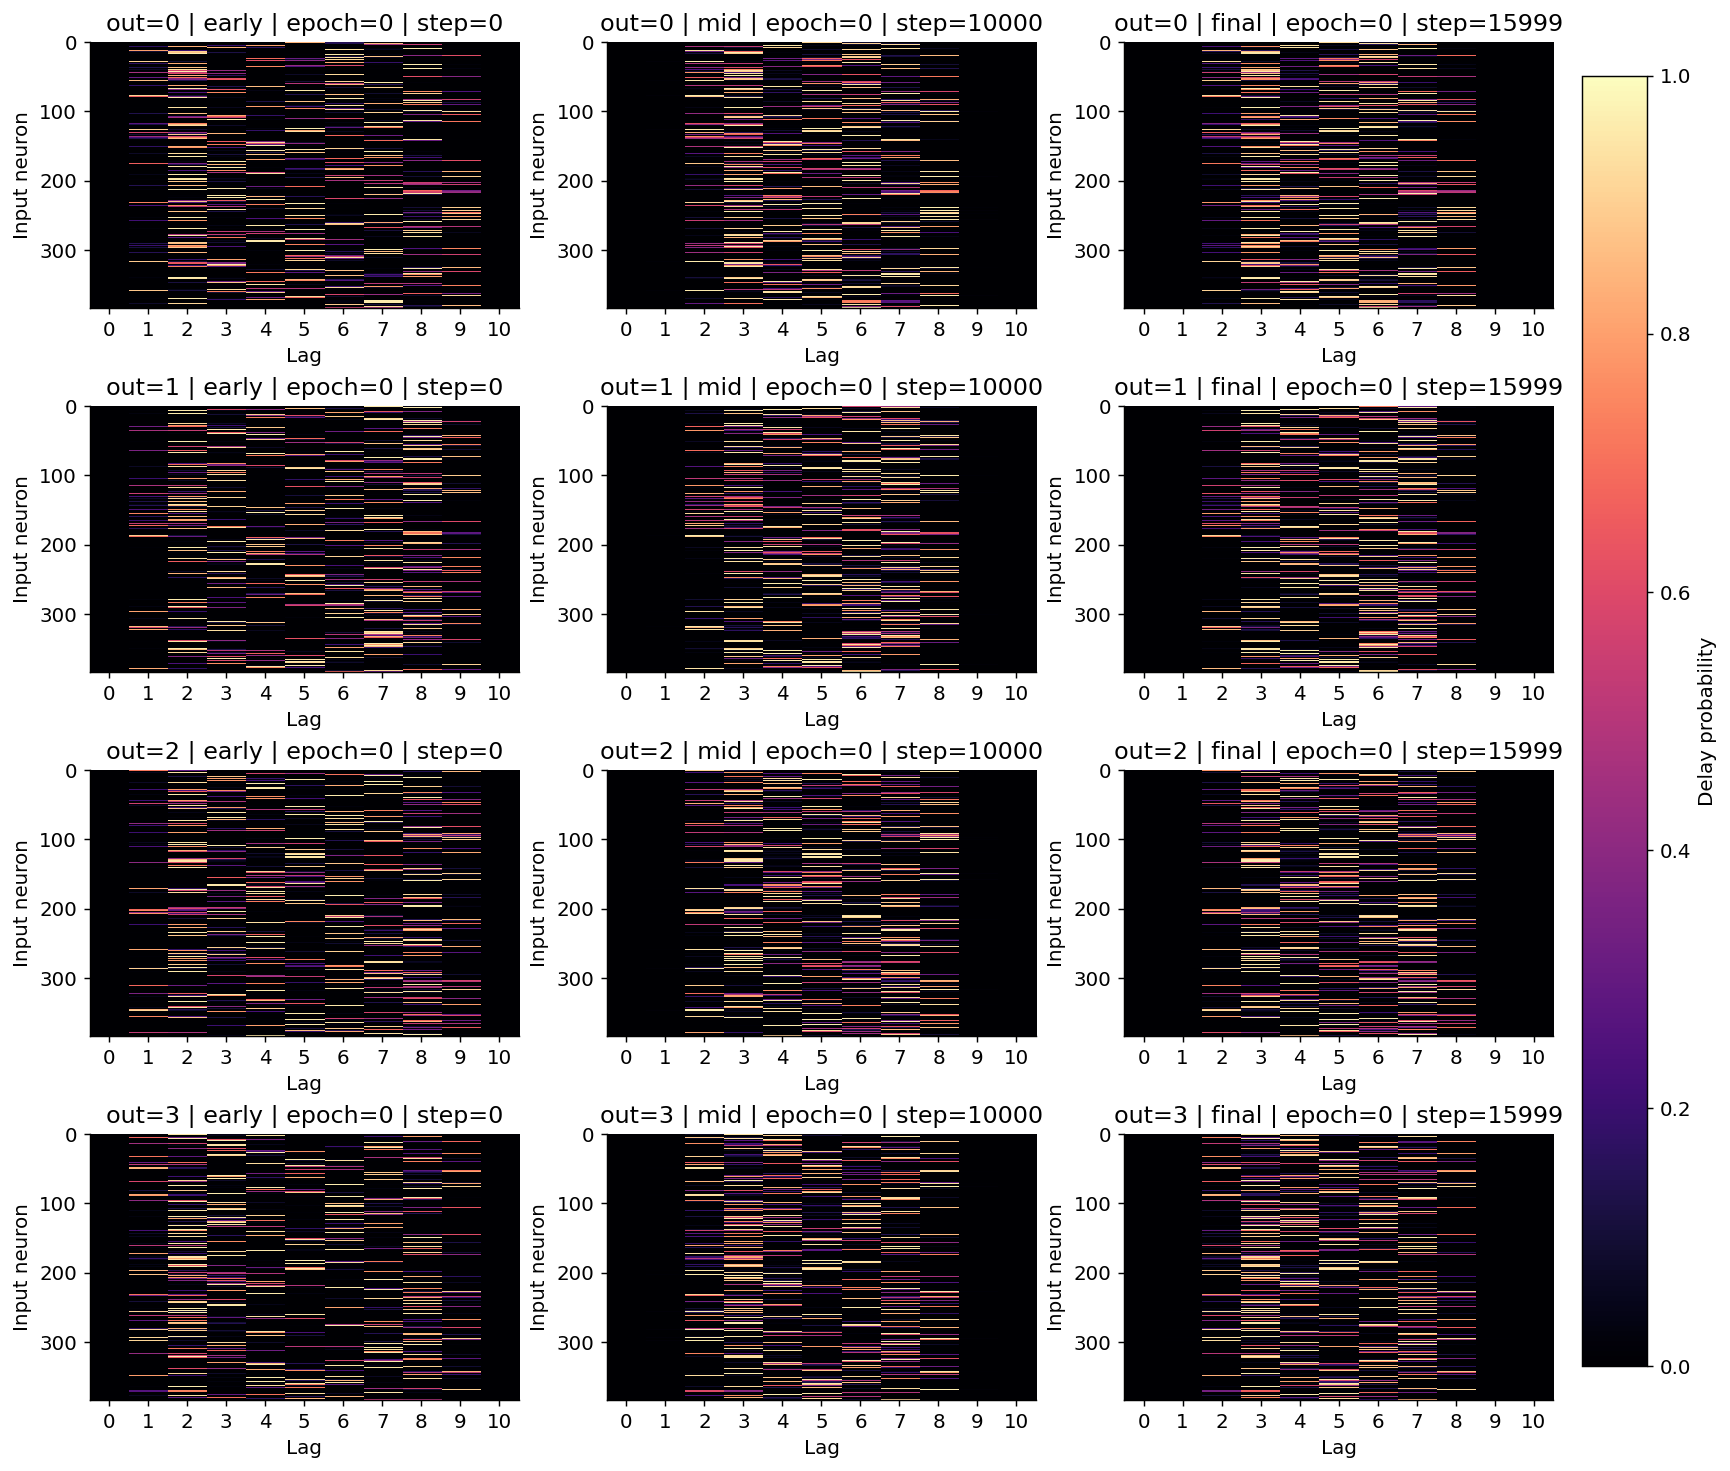

In [39]:
plot_delay_prob_heatmaps(stage_records, SELECTED_OUTPUT_NEURONS)
plt.show()

## Final discrete delay map

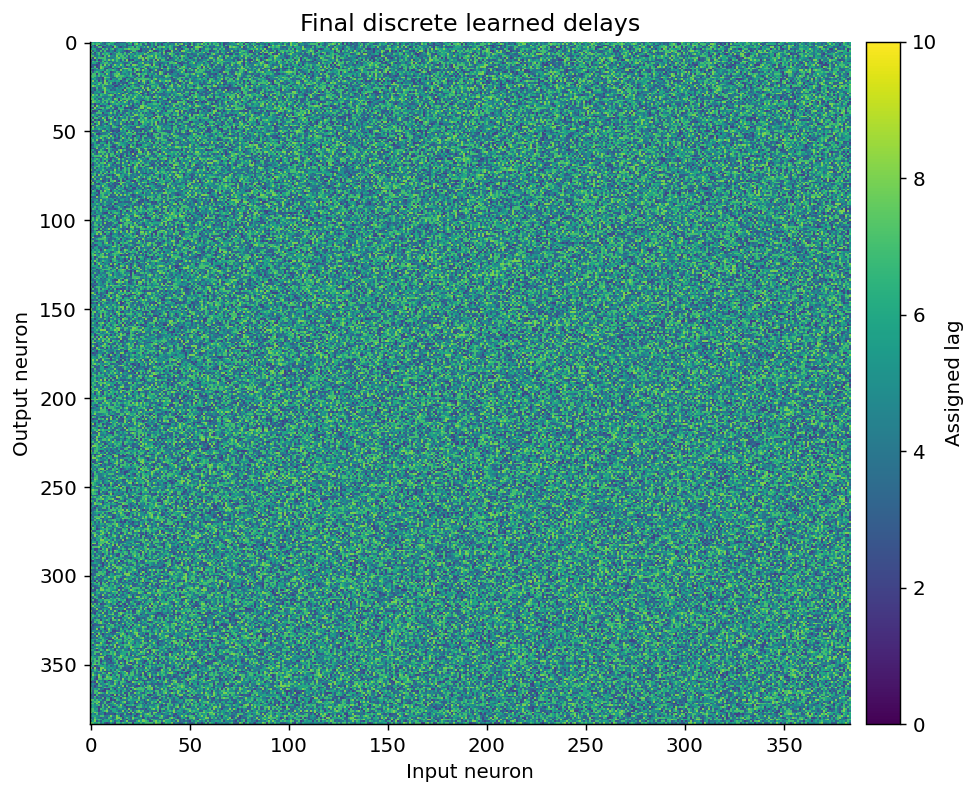

In [40]:
plot_final_discrete_delay_heatmap(final_record, prefer_onehot=PREFER_ONEHOT_FOR_FINAL_HEATMAP)
plt.show()

## Delay histograms across checkpoints

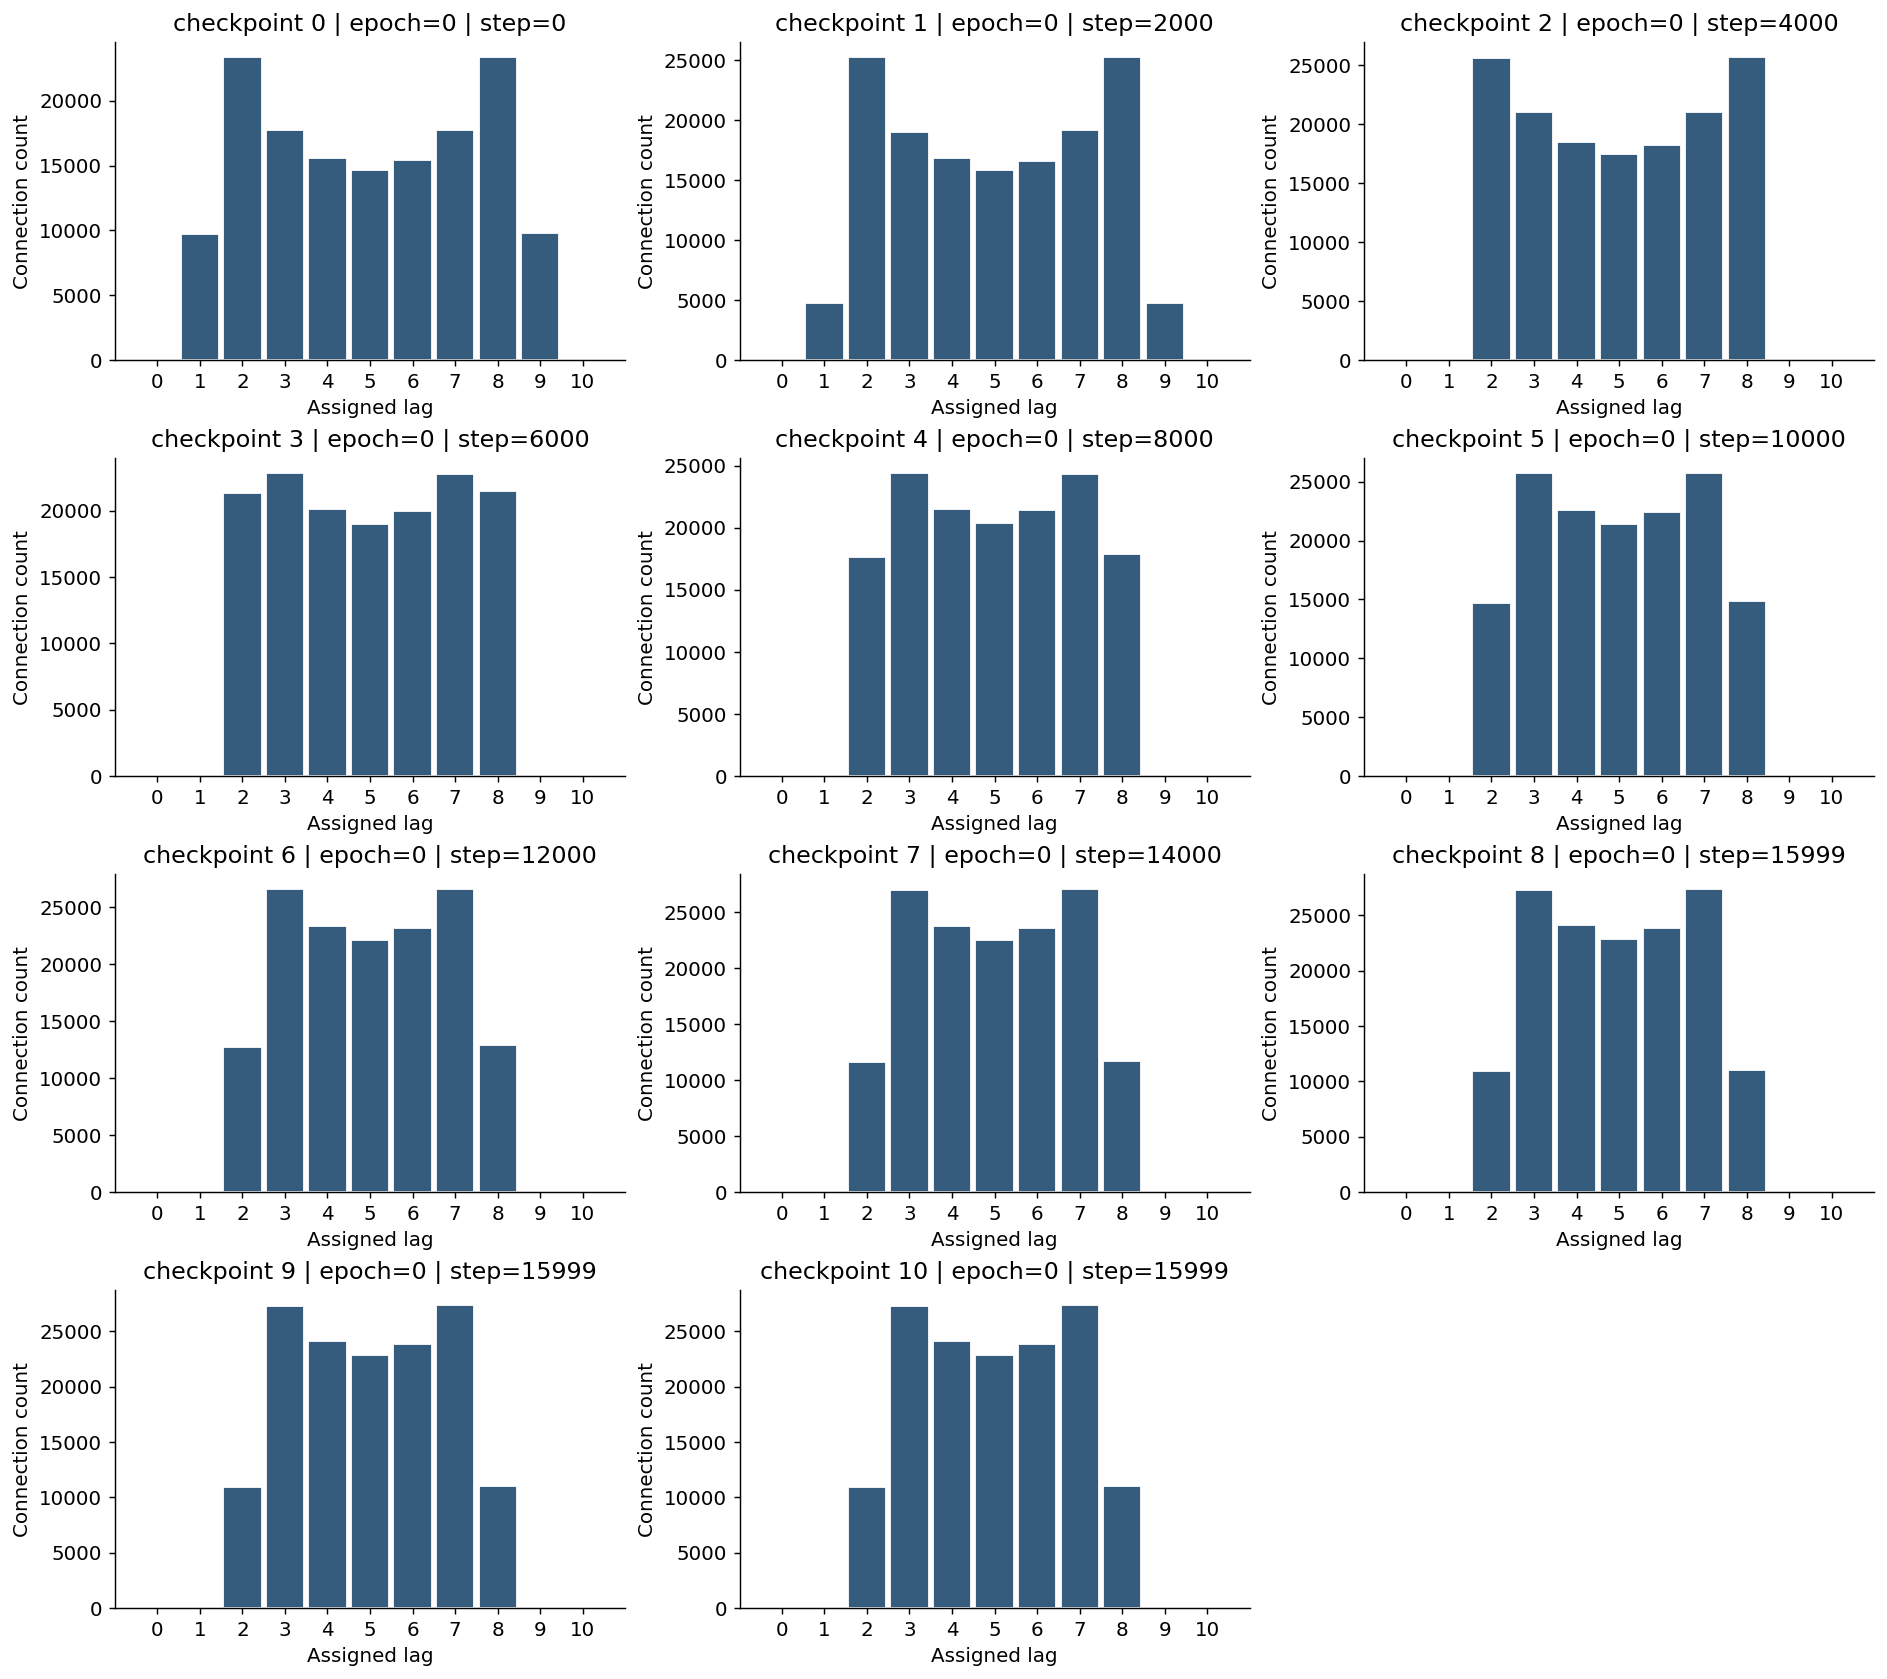

In [41]:
plot_delay_histograms_over_time(records)
plt.show()

## Fraction of connections assigned to each lag over time

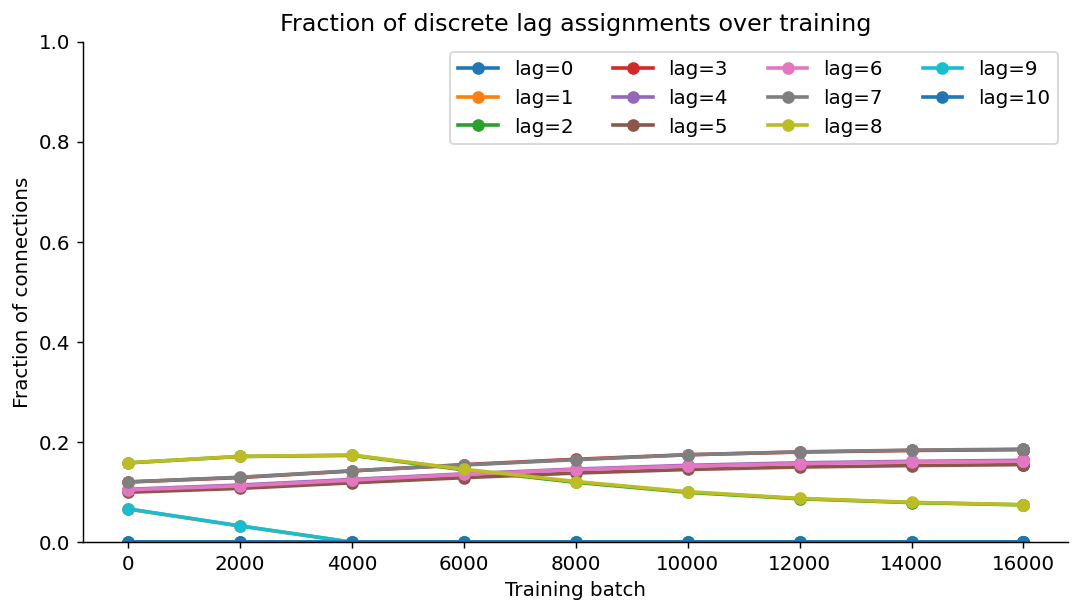

ValueError: Index contains duplicate entries, cannot reshape

In [42]:
_, _, lag_fraction_table = plot_lag_fraction_over_time(records, x_axis_mode=LAG_FRACTION_X_AXIS)
plt.show()
display(lag_fraction_table.pivot(index="lag", columns="x", values="fraction"))

## Relation between delay and absolute weight

/tmp/ipykernel_313720/3578268462.py:95: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(box_data, labels=[str(lag) for lag in lags], showfliers=False)


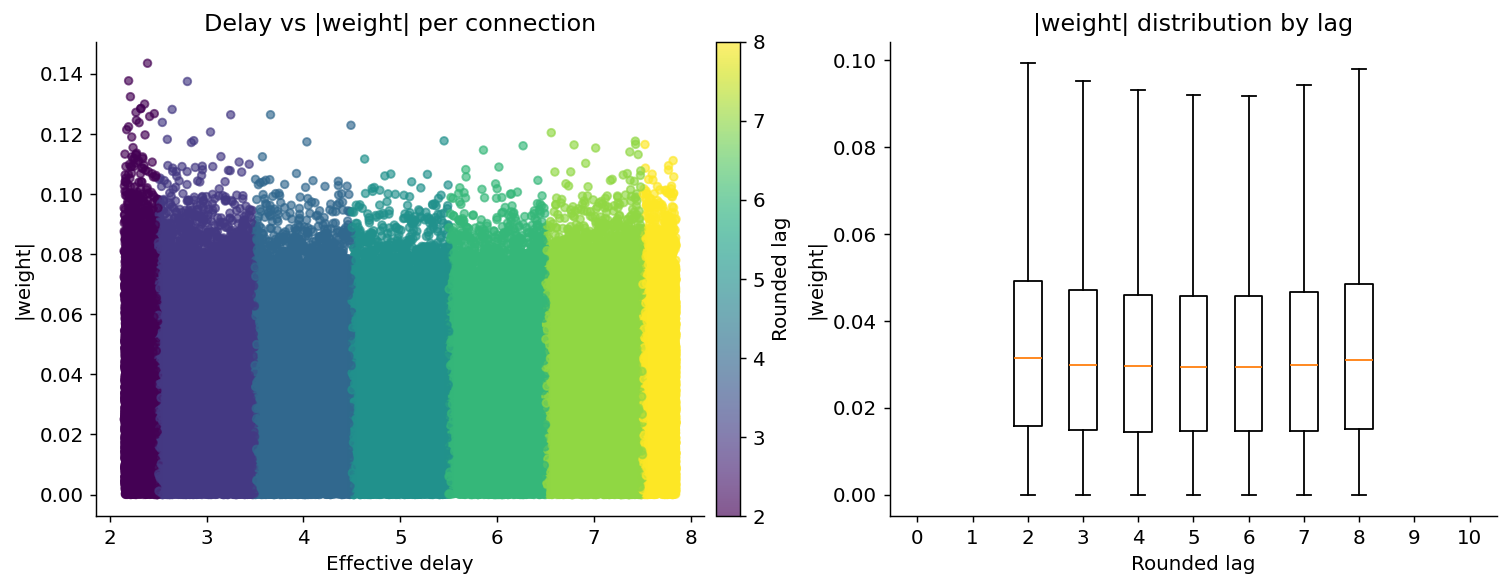

In [43]:
plot_delay_vs_weight(final_record)
plt.show()

## Suppressed or unused lags

In [44]:
lag_summary = build_lag_summary(records)
display(lag_summary)

highlight_row = lag_summary.loc[lag_summary["lag"] == TARGET_LAG_TO_HIGHLIGHT]
if not highlight_row.empty:
    row = highlight_row.iloc[0]
    display(Markdown(
        f"**Lag {int(row['lag'])} status:** `{row['status']}`  "
        f"Final fraction = `{row['final_fraction']:.3f}`, "
        f"max fraction over time = `{row['max_fraction_over_time']:.3f}`, "
        f"final mean soft probability = `{row['final_mean_soft_prob']:.3f}`"
    ))
else:
    display(Markdown(f"Lag `{TARGET_LAG_TO_HIGHLIGHT}` is not present in `lags={lags.tolist()}`."))

suppressed = lag_summary.loc[lag_summary["status"] != "active", ["lag", "status", "final_fraction", "max_fraction_over_time"]]
display(Markdown("**Non-active lags**"))
display(suppressed if not suppressed.empty else pd.DataFrame({"message": ["No lags were classified as suppressed or unused."]}))

,lag,final_fraction,max_fraction_over_time,final_mean_soft_prob,final_weighted_soft_prob,final_count,status
0,0,0.000000,0.000000,1.151126e-10,1.242477e-10,0,unused
1,1,0.000000,0.066074,1.181301e-04,1.267344e-04,0,suppressed
2,2,0.074402,0.173367,7.440744e-02,7.908445e-02,10971,active
3,3,0.184848,0.184848,1.843426e-01,1.865448e-01,27257,active
4,4,0.163472,0.163472,1.633835e-01,1.605553e-01,24105,active
5,5,0.154894,0.154894,1.553495e-01,1.521756e-01,22840,active
6,6,0.161689,0.161689,1.625789e-01,1.594601e-01,23842,active
7,7,0.185818,0.185818,1.845452e-01,1.844732e-01,27400,active
8,8,0.074877,0.174201,7.511390e-02,7.740812e-02,11041,active
9,9,0.000000,0.066501,1.195194e-04,1.237526e-04,0,suppressed


**Lag 1 status:** `suppressed`  Final fraction = `0.000`, max fraction over time = `0.066`, final mean soft probability = `0.000`

**Non-active lags**

,lag,status,final_fraction,max_fraction_over_time
0,0,unused,0.0,0.000000
1,1,suppressed,0.0,0.066074
9,9,suppressed,0.0,0.066501
10,10,unused,0.0,0.000000


## Input Lag Autocorrelation

In [ ]:
input_autocorr = run_input_autocorr_analysis(
    run_dir,
    max_lag=INPUT_AUTOCORR_MAX_LAG,
    analyze_raw=ANALYZE_RAW_INPUT_AUTOCORR,
    analyze_smoothed=ANALYZE_SMOOTHED_INPUT_AUTOCORR,
    max_trials=INPUT_AUTOCORR_MAX_TRIALS,
)

summary_rows = []
for label, result in input_autocorr["results"].items():
    summary_rows.append({
        "view": label,
        "num_trials": result["num_trials"],
        "num_channels": result["num_channels"],
        "mean_trial_length": result["trial_length_mean"],
        "min_trial_length": result["trial_length_min"],
        "max_trial_length": result["trial_length_max"],
    })

display(Markdown(
    f"**Input autocorrelation run:** `{input_autocorr['run_dir']}`  \n"
    f"**Config source:** `{input_autocorr['config_path']}`"
))
display(pd.DataFrame(summary_rows))

for label, result in input_autocorr["results"].items():
    display(Markdown(f"### Mean Autocorrelation Table: `{label}`"))
    display(result["mean_table"])

In [ ]:
plot_mean_autocorr_curves(input_autocorr)
plt.show()

for label in input_autocorr["results"].keys():
    plot_per_channel_autocorr(input_autocorr, which=label)
    plt.show()
    plot_channel_lag_heatmap(input_autocorr, which=label)
    plt.show()

In [ ]:
for label, result in input_autocorr["results"].items():
    interpretation = interpret_autocorr(result["mean_table"])
    display(Markdown(f"**Interpretation ({label})**: {interpretation}"))